In [56]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from dotenv import load_dotenv
from typing import TypedDict, Annotated
from pydantic import BaseModel, Field
import operator

In [57]:
load_dotenv()

True

In [58]:
model = ChatGroq(
    model='openai/gpt-oss-20b',
)

In [59]:
class EvaluationSchema(BaseModel):

    feedback: str = Field(description='Detailed feedback for the essay')
    score: int = Field(description='Score out of 10',ge=0 , le=10)


In [60]:
structured_model = model.with_structured_output(EvaluationSchema)


In [61]:
essay = """ 
# Artificial Intelligence

Artificial Intelligence (AI) is one of the most important technologies of the modern world. It refers to the ability of machines and computer systems to perform tasks that normally require human intelligence, such as understanding language, recognizing images, solving problems, making decisions, and learning from data. AI is rapidly changing the way people live, work, communicate, and solve real-world problems.

AI is used in many areas of our daily lives. Search engines use AI to provide relevant results, recommendation systems suggest movies and products based on user preferences, and virtual assistants can understand and respond to human commands. In healthcare, AI can help doctors analyze medical images, identify diseases, and assist in medical research. In education, AI-powered tools can provide personalized learning experiences and help students understand difficult concepts.

One of the major developments in AI is Generative AI. Unlike traditional AI systems that mainly analyze existing information, Generative AI can create new content such as text, images, audio, video, and computer code. Large Language Models (LLMs) are an important example of Generative AI. They can understand natural language and generate human-like responses, making them useful for chatbots, coding assistants, content creation, research, and many other applications.

AI also provides significant benefits to businesses. It can automate repetitive tasks, analyze large amounts of data, improve decision-making, and increase productivity. Companies can use AI to understand customer behavior, detect fraud, optimize operations, and develop new products and services. As AI technology continues to improve, it is becoming an important part of software development and modern business strategies.

However, AI also creates several challenges. Issues such as data privacy, security, bias, misinformation, and the impact of automation on employment need to be addressed carefully. AI systems can also produce incorrect information if they are trained or used improperly. Therefore, AI should be developed and used responsibly, with appropriate human supervision and ethical considerations.

In conclusion, Artificial Intelligence has enormous potential to transform society. It can improve productivity, solve complex problems, and create new opportunities across different fields. At the same time, its risks must be managed responsibly. The future of AI will depend not only on how powerful these technologies become, but also on how responsibly humans develop and use them.

"""

In [62]:
essay1 = """The Role of Social Media in Modern Democracy

Social media has become an important part of modern society. Platforms such as Facebook, X, Instagram and YouTube have changed the way people communicate, access information and participate in public life. In a democracy, where the participation and opinions of citizens are important, social media can provide both opportunities and challenges.

One of the major advantages of social media is that it gives ordinary citizens a platform to express their opinions. People can discuss social issues, raise concerns and communicate with government representatives. During elections, political parties can use social media to reach a large number of voters and explain their policies. Social media has therefore reduced the distance between citizens and political institutions.

Social media can also increase awareness about important issues. Information about government schemes, disasters, environmental problems and social movements can spread rapidly. It can help people organise peaceful campaigns and bring attention to issues that may otherwise receive little attention from traditional media.

However, social media can also create serious problems for democracy. False information can spread very quickly and influence public opinion. Political propaganda, manipulated videos and fake accounts can mislead citizens. Social media algorithms may also create echo chambers where people mainly see opinions similar to their own. This can increase political polarisation and reduce meaningful debate.

Another concern is the misuse of personal data. Social media platforms collect large amounts of information about users, which can potentially be used to influence their behaviour and political preferences. Therefore, freedom of expression must be balanced with privacy, accountability and responsible use of technology.

Social media is neither inherently beneficial nor harmful to democracy. Its impact depends on how citizens, governments, political parties and technology companies use it. Stronger digital literacy, transparent platform policies, protection of personal data and effective action against deliberate misinformation can help reduce its negative effects.

Thus, social media can strengthen modern democracy by giving citizens greater voice and access to information. At the same time, it can weaken democratic institutions if it becomes a tool for manipulation and misinformation. The challenge is not to restrict communication, but to create an environment where citizens can participate freely while making informed decisions."""

In [ ]:
prompt = f'Evaulate the language quality of the following essay and score it out of 10. Here is the essay \n {essay}'
structured_model.invoke(prompt)

EvaluationSchema(feedback='The essay demonstrates clear, concise, and coherent language appropriate for an academic discussion. The writer maintains a consistent, formal tone throughout, using varied sentence structures and a logical progression of ideas. Vocabulary is largely accurate and precise, with terms like "echo chambers," "misinformation," and "digital literacy" fitting the context. Paragraphs are well‑structured, each beginning with a topic sentence, followed by supporting details and a concluding thought. The transitions between advantages and disadvantages are smooth, and the conclusion succinctly summarizes the balanced view. Minor improvements could include more varied syntactic complexity and occasional use of more advanced academic connectors to elevate the prose. Overall, the language quality is strong and effectively supports the essay’s arguments.\n', score=9)

In [64]:
class UPSCState(TypedDict):
    essay: str
    language_feedback: str
    analysis_feedback: str
    clarity_feedback: str
    overall_feedback: str
    individual_score: Annotated[list[int],operator.add]
    avg_score: float 


In [65]:
def evaluate_language(state:UPSCState):
    prompt = f'Evaulate the language quality of the following essay and score it out of 10. Here is the essay \n {state["essay"]}'
    output = structured_model.invoke(prompt)
    return {'language_feedback': output.feedback, 'individual_score': [output.score]}
    

In [66]:
def evaluate_analysis(state:UPSCState):
    prompt = f'Evaulate the analysis of the following essay and score it out of 10. Here is the essay \n {state["essay"]}'
    output = structured_model.invoke(prompt)
    return {'analysis_feedback': output.feedback, 'individual_score': [output.score]}
    

In [67]:
def evaluate_thought(state:UPSCState):
    prompt = f'Evaulate the clarity of thought of the following essay and score it out of 10. Here is the essay \n {state["essay"]}'
    output = structured_model.invoke(prompt)
    return {'clarity_feedback': output.feedback, 'individual_score': [output.score]}
    

In [68]:
def final_evaluation(state: UPSCState):
    prompt = f'Based on the following feedbacks create a summarized feedback \n language feedback - {state["language_feedback"]} \n depth of analysis feedback - {state["analysis_feedback"]} \n clarity feedback - {state["clarity_feedback"]}'
    overall_feedback = model.invoke(prompt).content
    avg_score = sum(state['individual_score']) / len(state['individual_score'])
    return {'overall_feedback': overall_feedback, 'avg_score': avg_score}


In [69]:
graph = StateGraph(UPSCState)

graph.add_node('evaluate_language',evaluate_language)
graph.add_node('evaluate_analysis',evaluate_analysis)
graph.add_node('evaluate_thought',evaluate_thought)
graph.add_node('final_evaulation',final_evaluation)



In [70]:
graph.add_edge(START,'evaluate_language')
graph.add_edge(START,'evaluate_analysis')
graph.add_edge(START,'evaluate_thought')
graph.add_edge('evaluate_language','final_evaulation')
graph.add_edge('evaluate_analysis','final_evaulation')
graph.add_edge('evaluate_thought','final_evaulation')
graph.add_edge('final_evaulation',END)

workflow = graph.compile()

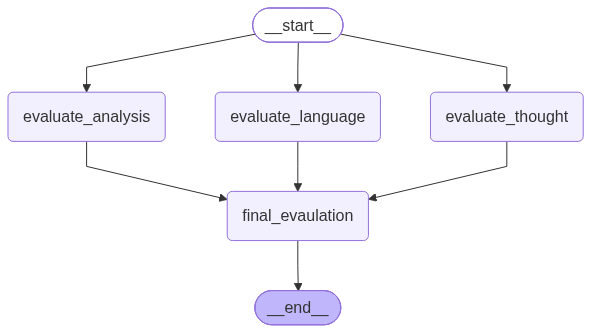

In [71]:
workflow

In [72]:
initial_state = {
    'essay': essay1
}
workflow.invoke(initial_state)

{'essay': 'The Role of Social Media in Modern Democracy\n\nSocial media has become an important part of modern society. Platforms such as Facebook, X, Instagram and YouTube have changed the way people communicate, access information and participate in public life. In a democracy, where the participation and opinions of citizens are important, social media can provide both opportunities and challenges.\n\nOne of the major advantages of social media is that it gives ordinary citizens a platform to express their opinions. People can discuss social issues, raise concerns and communicate with government representatives. During elections, political parties can use social media to reach a large number of voters and explain their policies. Social media has therefore reduced the distance between citizens and political institutions.\n\nSocial media can also increase awareness about important issues. Information about government schemes, disasters, environmental problems and social movements can 